In [34]:
# COMMIT 1: Dataset Exploration and Exploratory Data Analysis
# Implementation Scope:
# - Centralized parameter definitions localized to notebook memory cells.
# - Statistical class frequency profiling and target balance analysis.
# - Image resolution checks to mathematically justify a 224x224 crop choice.
# - 8-class sample validation visualization grid.


# importing libraries for system operations and randomization
import os
import random
from pathlib import Path

# importing libraries for data manipulation and visualization
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
from PIL import Image

# setting up configuration parameters for the project
CONFIG = {
    "labels_csv": Path("./train_labels.csv"),
    "train_dir": Path("./train"),
    "test_dir": Path("./test"),
    "image_size": (224, 224),
    "batch_size": 64,
    "num_workers": 0,
    "pin_memory": True,           
    "persistent_workers": False,
    "seed": 42,
    "profile_sample_size": 3000,
    "image_extensions": {".jpg", ".jpeg", ".png"},
    "classes": (
        "CatEye", "DogEye", "CatFace", "DogFace",
        "CatMouth", "DogMouth", "CatNose", "DogNose",
    ),
}

# defining a function to set random seeds for reproducibility
def seed_everything(seed):
    os.environ["PYTHONHASHSEED"] = str(seed)
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

# setting the random seed for reproducibility and configuring the visualization theme
seed_everything(CONFIG["seed"])
sns.set_theme(style="whitegrid", context="notebook")
print(f"seed={CONFIG['seed']} | target size={CONFIG['image_size']} | batch size={CONFIG['batch_size']}")

seed=42 | target size=(224, 224) | batch size=64


Total labelled samples: 63,660

          count  percent
class                   
CatEye    13884    21.81
DogEye    11580    18.19
CatFace    6942    10.90
DogFace    5790     9.10
CatMouth   6942    10.90
DogMouth   5790     9.10
CatNose    6942    10.90
DogNose    5790     9.10

Imbalance ratio (majority/minority): 2.398:1 (CatEye = 13,884, DogFace = 5,790)


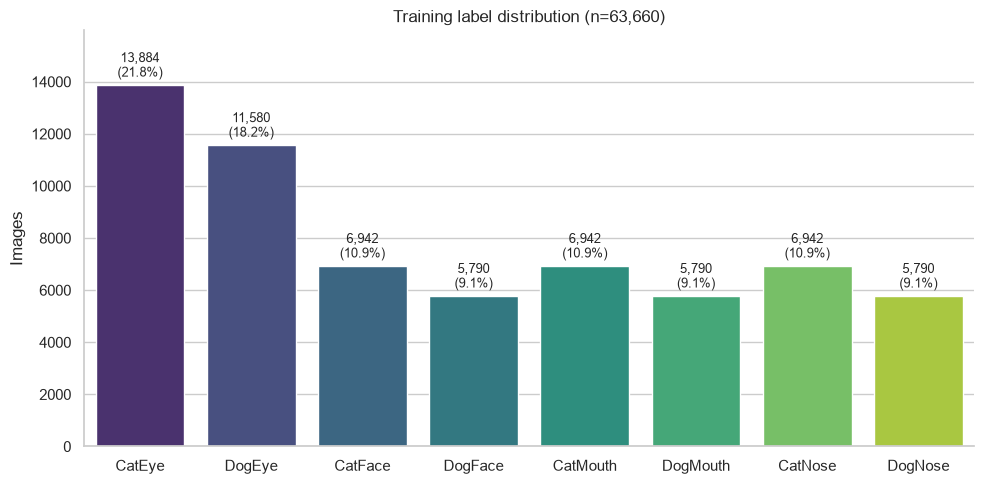

In [35]:
labels = pd.read_csv(CONFIG["labels_csv"], dtype={"image_id": str}) # reading the labels CSV file into a pandas DataFrame
classes = CONFIG["classes"] # defining the expected classes for the dataset 

unexpected = set(labels["class"]) - set(classes) # checking for any unexpected labels in the dataset
assert not unexpected, f"Unexpected labels: {sorted(unexpected)}" # checking for duplicate image_id values in the labels DataFrame
assert labels["image_id"].is_unique, "Duplicate image_id values in labels" # checking for any null values in the 'class' column of the labels DataFrame
assert labels["class"].notna().all(), "Null labels present" # checking for any null values in the 'image_id' column of the labels DataFrame

distribution = labels["class"].value_counts().reindex(classes).rename("count").to_frame() # creating a DataFrame to hold the count of each class in the dataset
distribution["percent"] = distribution["count"] / distribution["count"].sum() * 100 # calculating the percentage of each class in the dataset

print(f"Total labelled samples: {len(labels):,}\n")
# displaying the distribution of classes in the dataset, rounded to two decimal places
print(distribution.assign(percent=distribution["percent"].round(2)).to_string()) 
majority_class, minority_class = distribution["count"].idxmax(), distribution["count"].idxmin() # identifying the majority and minority classes in the dataset
imbalance_ratio = distribution["count"].max() / distribution["count"].min() # calculating the imbalance ratio between the majority and minority classes in the dataset
print(f"\nImbalance ratio (majority/minority): {imbalance_ratio:.3f}:1 " 
      f"({majority_class} = {distribution['count'].max():,}, {minority_class} = {distribution['count'].min():,})") # displaying the imbalance ratio

# visualizing the distribution of classes in the dataset using a bar plot
fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(
    data=distribution.reset_index(names="class"),
    x="class", y="count", hue="class", order=classes,
    palette="viridis", legend=False, ax=ax,
)
# annotating the bar plot with the count and percentage of each class
for position, (_, row) in enumerate(distribution.iterrows()):
    ax.annotate(
        f"{int(row['count']):,}\n({row['percent']:.1f}%)",
        (position, row["count"]), xytext=(0, 3), textcoords="offset points",
        ha="center", va="bottom", fontsize=9,
    )

# setting the y-axis limits, labels, and title for the bar plot
ax.set_ylim(0, distribution["count"].max() * 1.15)
ax.set_xlabel("")
ax.set_ylabel("Images")
ax.set_title(f"Training label distribution (n={len(labels):,})")
sns.despine(ax=ax) 
fig.tight_layout()
plt.show()

Train images on disk: 63,660 | labelled: 63,660 | labels without file: 0 | files without label: 0
Test images on disk: 29,443

--- train: 3,000 sampled, 0 corrupted ---
                 min        max      mean  median
width           4.00     978.00    111.26    84.0
height          4.00     989.00    107.46    80.0
aspect_ratio    0.47       4.25      1.06     1.0
bytes         673.00  317708.00  10060.10  4306.0
channel modes: {'RGB': 3000}
non-square (aspect ratio outside 0.95-1.05): 30.6%
upscaled to 224 (short side < 224): 93.1%
downscaled to 224 (long side > 224): 9.8%

--- test: 3,000 sampled, 0 corrupted ---
                 min        max      mean  median
width           8.00    1442.00    113.71    82.5
height          9.00    1443.00    110.32    80.0
aspect_ratio    0.44       4.44      1.07     1.0
bytes         693.00  520442.00  10611.03  4247.5
channel modes: {'RGB': 3000}
non-square (aspect ratio outside 0.95-1.05): 55.3%
upscaled to 224 (short side < 224): 91.8%
dow

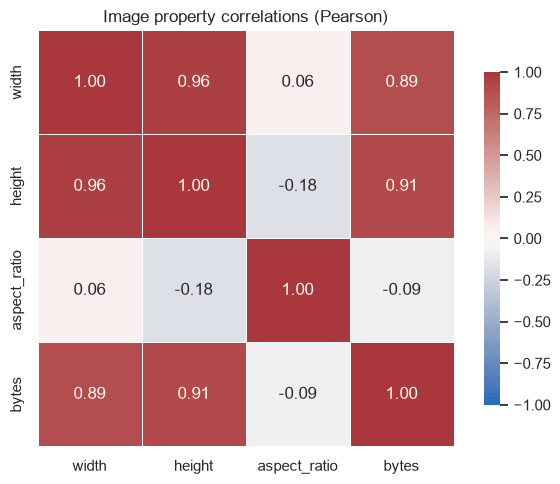

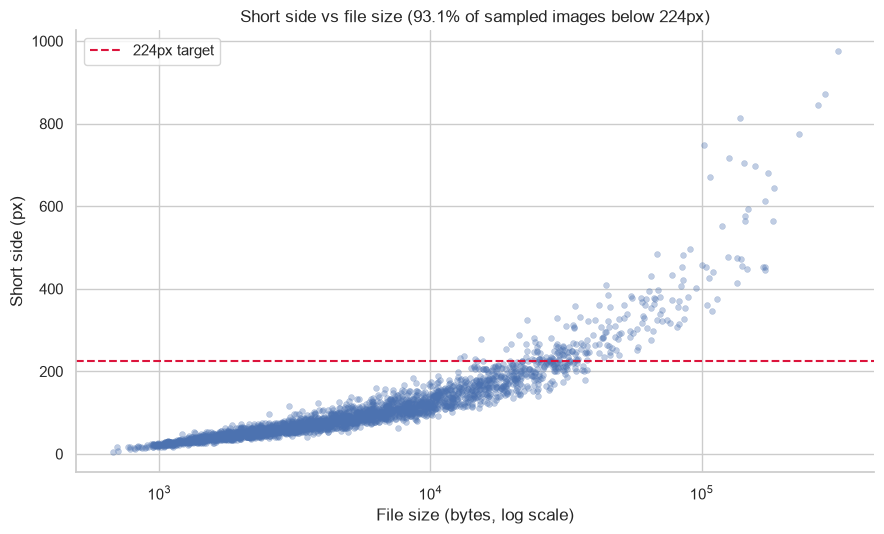

In [36]:
# defining a function to list image files in a directory based on specified extensions
def list_images(directory):
    return sorted(p for p in directory.iterdir() if p.suffix.lower() in CONFIG["image_extensions"])

# defining a function to profile images by sampling and collecting their properties
def profile_images(paths, sample_size, seed):
    sample = random.Random(seed).sample(paths, min(sample_size, len(paths)))
    records, corrupted = [], []
    for path in sample:
        try:
            with Image.open(path) as img:
                img.verify()
            with Image.open(path) as img:
                img.load()
                records.append({
                    "file": path.name,
                    "width": img.width,
                    "height": img.height,
                    "channels": len(img.getbands()),
                    "mode": img.mode,
                    "bytes": path.stat().st_size,
                })
        except Exception as exc:
            corrupted.append((path.name, repr(exc))) # appending the name of the corrupted file and the exception message to the corrupted list
    frame = pd.DataFrame(records) # creating a DataFrame from the records list to hold the properties of the sampled images
    frame["aspect_ratio"] = frame["width"] / frame["height"] # calculating the aspect ratio of each image and adding it as a new column in the DataFrame
    return frame, corrupted # returning the DataFrame containing the properties of the sampled images and the list of corrupted files

# defining a function to report the profile of images, including statistics and information about corrupted files
def report_profile(name, frame, corrupted, target):
    stats = frame[["width", "height", "aspect_ratio", "bytes"]].agg(["min", "max", "mean", "median"]).T
    short_side = frame[["width", "height"]].min(axis=1)
    long_side = frame[["width", "height"]].max(axis=1)
    print(f"--- {name}: {len(frame):,} sampled, {len(corrupted)} corrupted ---")
    print(stats.round(2).to_string())
    print("channel modes:", frame["mode"].value_counts().to_dict())
    print(f"non-square (aspect ratio outside 0.95-1.05): {((frame['aspect_ratio'] < 0.95) | (frame['aspect_ratio'] > 1.05)).mean():.1%}")
    print(f"upscaled to {target} (short side < {target}): {(short_side < target).mean():.1%}")
    print(f"downscaled to {target} (long side > {target}): {(long_side > target).mean():.1%}")
    for file_name, error in corrupted[:5]:
        print(f"  corrupted: {file_name} -> {error}")
    print()


train_files = list_images(CONFIG["train_dir"]) #listing the image files in the training directory based on specified extensions
test_files = list_images(CONFIG["test_dir"]) #listing the image files in the test directory based on specified extensions

label_ids = set(labels["image_id"]) # creating a set of image IDs from the labels DataFrame for comparison with the files on disk
file_ids = {p.stem for p in train_files} # creating a set of image IDs from the training files on disk for comparison with the labels DataFrame
# printing the counts of training and test images on disk, labelled images, and any discrepancies between the labels and files
print(f"Train images on disk: {len(train_files):,} | labelled: {len(label_ids):,} | "
      f"labels without file: {len(label_ids - file_ids):,} | files without label: {len(file_ids - label_ids):,}")
print(f"Test images on disk: {len(test_files):,}\n")
assert not label_ids - file_ids, "Some labelled images are missing from the train folder" # asserting that all labelled images are present in the training folder

# profiling the training and test images, and reporting their properties and any corrupted files
target = CONFIG["image_size"][0]
train_profile, train_corrupted = profile_images(train_files, CONFIG["profile_sample_size"], CONFIG["seed"])
test_profile, test_corrupted = profile_images(test_files, CONFIG["profile_sample_size"], CONFIG["seed"])
report_profile("train", train_profile, train_corrupted, target) #reporting the profile of the training images, including statistics and information about corrupted files
report_profile("test", test_profile, test_corrupted, target) #reporting the profile of the test images, including statistics and information about corrupted files

# added 2 more exploratory data analysis visualizations to the notebook, including a heatmap of the Pearson correlation matrix for image properties and a scatter plot showing the relationship between file size and short side of the images in the training profile DataFrame
# adding a new column to the training profile DataFrame to hold the short side of each image, which is the minimum of its width and height
profile = train_profile.assign(short_side=train_profile[["width", "height"]].min(axis=1))

# calculating the Pearson correlation matrix for the width, height, aspect ratio, and bytes columns of the training profile DataFrame
correlation = profile[["width", "height", "aspect_ratio", "bytes"]].corr(method="pearson")
fig, ax = plt.subplots(figsize=(6.5, 5))
sns.heatmap(
    correlation, annot=True, fmt=".2f", cmap="vlag", vmin=-1, vmax=1,
    square=True, linewidths=0.5, cbar_kws={"shrink": 0.8}, ax=ax,
) # creating a heatmap to visualize the Pearson correlation matrix, with annotations, color mapping, and formatting options
ax.set_title("Image property correlations (Pearson)")
fig.tight_layout()
plt.show()

# visualizing the relationship between file size and short side of the images in the training profile DataFrame using a scatter plot
upscaled_share = (profile["short_side"] < target).mean()
fig, ax = plt.subplots(figsize=(9, 5.5)) # creating a new figure and axis for the scatter plot with specified dimensions
sns.scatterplot(data=profile, x="bytes", y="short_side", alpha=0.35, s=18, edgecolor=None, ax=ax)
ax.axhline(target, color="crimson", linestyle="--", linewidth=1.5, label=f"{target}px target")
ax.set_xscale("log")
ax.set_xlabel("File size (bytes, log scale)")
ax.set_ylabel("Short side (px)")
ax.set_title(f"Short side vs file size ({upscaled_share:.1%} of sampled images below {target}px)") # setting the title of the scatter plot to indicate the relationship between short side and file size, and the percentage of sampled images below the target size
ax.legend(loc="upper left")
sns.despine(ax=ax)
fig.tight_layout()
plt.show()

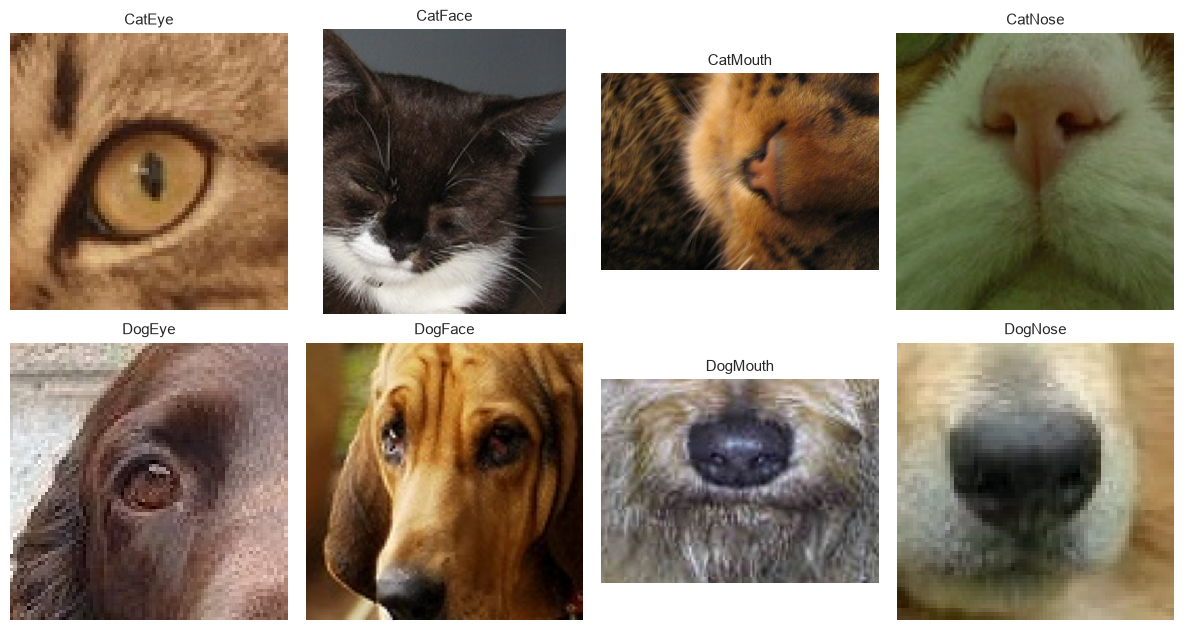

In [37]:
# visualizing a grid of sample images from each class in the training dataset
path_by_id = {p.stem: p for p in train_files}
ids_by_class = labels.groupby("class")["image_id"].apply(list)
grid_layout = [
    ["CatEye", "CatFace", "CatMouth", "CatNose"],
    ["DogEye", "DogFace", "DogMouth", "DogNose"],
]
# setting the random seed for reproducibility and creating a grid of subplots to display sample images from each class
rng = random.Random(CONFIG["seed"])
fig, axes = plt.subplots(2, 4, figsize=(12, 6.5))
for row_axes, row_classes in zip(axes, grid_layout):
    for ax, class_name in zip(row_axes, row_classes):
        with Image.open(path_by_id[rng.choice(ids_by_class[class_name])]) as img:
            ax.imshow(img.convert("RGB"))
        ax.set_title(class_name, fontsize=11)
        ax.axis("off")
fig.tight_layout()
plt.show()

In [38]:
# COMMIT 2: Data Leakage Protection and Custom Dataset Loaders

# Implementation Scope:
# - Stratified 80/20 train-validation split preserving baseline skews.
# - Custom PyTorch Dataset class parsing disk paths from string IDs on-the-fly.
# - Leak-free pipeline isolating augmentations entirely from validation arrays.
# - Optimized, multi-threaded batch DataLoader instantiations.

# importing libraries for hashing and data loading
import hashlib

from sklearn.model_selection import StratifiedGroupKFold
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms

# defining a function to compute the MD5 hash of a file's contents
CONFIG.update({
    "val_fraction": 0.2, # defining the fraction of the dataset to be used for validation
    "imagenet_mean": (0.485, 0.456, 0.406), # defining the mean values for normalization based on ImageNet statistics
    "imagenet_std": (0.229, 0.224, 0.225), # defining the standard deviation values for normalization based on ImageNet statistics
    "pin_memory": torch.cuda.is_available(), # setting the pin_memory parameter based on whether CUDA is available for faster data transfer to GPU
    "persistent_workers": CONFIG["num_workers"] > 0, # setting the persistent_workers parameter based on whether num_workers is greater than 0 for efficient data loading
})

image_paths = {p.stem: p for p in list_images(CONFIG["train_dir"])} # creating a dictionary mapping image IDs to their corresponding file paths in the training directory


def file_digest(path):
    return hashlib.md5(path.read_bytes()).hexdigest() # defining a function to compute the MD5 hash of a file's contents for data leakage protection

# creating a new column in the labels DataFrame to store the MD5 hash of each image file's contents for data leakage protection
labels = labels.assign(digest=[file_digest(image_paths[i]) for i in labels["image_id"]]) 

# performing a stratified group K-fold split of the dataset into training and validation sets while preserving class distribution and avoiding data leakage
n_splits = round(1 / CONFIG["val_fraction"]) 
splitter = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=CONFIG["seed"])
# splitting the dataset into training and validation indices while ensuring that images with the same content (same digest) are not split across the two sets
train_idx, val_idx = next(splitter.split(labels, labels["class"], groups=labels["digest"]))
# creating separate DataFrames for the training and validation sets based on the indices obtained from the stratified group K-fold split
train_df = labels.iloc[train_idx].reset_index(drop=True)
val_df = labels.iloc[val_idx].reset_index(drop=True)

# displaying the counts and percentages of each class in the training and validation sets, rounded to two decimal places
split_counts = pd.DataFrame({
    "train": train_df["class"].value_counts(),
    "val": val_df["class"].value_counts(),
}).reindex(classes)
split_counts["train_pct"] = split_counts["train"] / split_counts["train"].sum() * 100
split_counts["val_pct"] = split_counts["val"] / split_counts["val"].sum() * 100
print(split_counts.round(2).to_string())

# checking for class imbalance in the training and validation sets and displaying the imbalance ratio for each set
for name, frame in (("train", train_df), ("val", val_df)):
    counts = frame["class"].value_counts()
    print(f"{name}: n={len(frame):,} ({len(frame) / len(labels):.1%}) | "
          f"imbalance {counts.max() / counts.min():.3f}:1")
    
# checking for any overlap in image IDs or content (digests) between the training and validation sets to ensure data leakage protection
id_overlap = set(train_df["image_id"]) & set(val_df["image_id"])
content_overlap = set(train_df["digest"]) & set(val_df["digest"])
assert len(train_df) + len(val_df) == len(labels) # ensuring that the total number of samples in the training and validation sets equals the total number of samples in the original labels DataFrame
assert not id_overlap and not content_overlap # ensuring that there is no overlap in image IDs or content (digests) between the training and validation sets to prevent data leakage
print(f"id overlap: {len(id_overlap)} | content overlap: {len(content_overlap)} | "
      f"duplicate-content images grouped: {int(labels['digest'].duplicated(keep=False).sum())}")

          train   val  train_pct  val_pct
class                                    
CatEye    11107  2777      21.81    21.81
DogEye     9264  2316      18.19    18.19
CatFace    5554  1388      10.91    10.90
DogFace    4632  1158       9.10     9.10
CatMouth   5554  1388      10.91    10.90
DogMouth   4632  1158       9.10     9.10
CatNose    5553  1389      10.90    10.91
DogNose    4632  1158       9.10     9.10
train: n=50,928 (80.0%) | imbalance 2.398:1
val: n=12,732 (20.0%) | imbalance 2.398:1
id overlap: 0 | content overlap: 0 | duplicate-content images grouped: 30


In [39]:
# defining a custom PyTorch Dataset class for loading pet images and their corresponding labels
class PetFeatureDataset(Dataset):
    def __init__(self, frame, image_dir, class_to_idx, transform=None, id_width=5): # initializing the dataset with the provided parameters
        self.transform = transform # storing the transformation function to be applied to the images
        available = {
            p.stem: p for p in Path(image_dir).iterdir()
            if p.suffix.lower() in CONFIG["image_extensions"] 
        } # creating a dictionary mapping available image IDs to their corresponding file paths in the specified image directory
        self.image_ids = [str(i).strip().zfill(id_width) for i in frame["image_id"]] # creating a list of image IDs from the provided DataFrame, ensuring they are zero-padded to the specified width
        missing = [i for i in self.image_ids if i not in available] # checking for any image IDs in the provided DataFrame that are not present in the available images dictionary
        if missing:
            raise FileNotFoundError(f"{len(missing)} image ids not found in {image_dir}, e.g. {missing[:5]}") # raising a FileNotFoundError if any image IDs in the provided DataFrame are not found in the available images dictionary, along with a sample of the missing IDs
        self.paths = [available[i] for i in self.image_ids]
        if "class" in frame.columns:
            self.targets = [class_to_idx[c] for c in frame["class"]] # creating a list of target labels corresponding to the image IDs in the provided DataFrame, using the class_to_idx mapping to convert class names to integer indices
        else:
            self.targets = [-1] * len(self.paths) # creating a list of target labels with a default value of -1 for images that do not have corresponding class labels in the provided DataFrame

    def __len__(self):
        return len(self.paths) # returning the total number of samples in the dataset, which is equal to the length of the paths list
    # implementing the __getitem__ method to retrieve a specific sample from the dataset
    def __getitem__(self, index):
        with Image.open(self.paths[index]) as img:
            image = img.convert("RGB") # converting the image to RGB format to ensure consistency in the number of channels
        if self.transform is not None:
            image = self.transform(image) # applying the specified transformation function to the image if it is provided
        return image, self.targets[index] # returning the transformed image and its corresponding target label for the specified index in the dataset

In [40]:
mean, std, size = CONFIG["imagenet_mean"], CONFIG["imagenet_std"], CONFIG["image_size"] # defining the mean, standard deviation, and target size for image normalization and resizing based on ImageNet statistics

# defining the transformation pipeline for training images, including data augmentation techniques such as random horizontal flipping, random rotation, and color jittering, followed by resizing, conversion to tensor, and normalization
train_transform = transforms.Compose([
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.02),
    transforms.Resize(size),
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
])

# defining the transformation pipeline for evaluation images, including resizing, conversion to tensor, and normalization
eval_transform = transforms.Compose([
    transforms.Resize(size),
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
])

In [41]:
# creating a mapping from class names to integer indices for use in the dataset
class_to_idx = {name: idx for idx, name in enumerate(classes)}
test_df = pd.DataFrame({"image_id": [p.stem for p in test_files]})

# creating instances of the custom PetFeatureDataset class for the training, validation, and test datasets, applying the appropriate transformations and using the class_to_idx mapping for target labels
train_dataset = PetFeatureDataset(train_df, CONFIG["train_dir"], class_to_idx, train_transform)
val_dataset = PetFeatureDataset(val_df, CONFIG["train_dir"], class_to_idx, eval_transform)
test_dataset = PetFeatureDataset(test_df, CONFIG["test_dir"], class_to_idx, eval_transform)

# defining a function to seed the random number generators for each worker in the DataLoader to ensure reproducibility
def seed_worker(worker_id):
    worker_seed = torch.initial_seed() % 2**32
    np.random.seed(worker_seed)
    random.seed(worker_seed)

# setting up keyword arguments for the DataLoader instances, including batch size, number of workers, pin memory, persistent workers, and the worker initialization function for seeding
loader_kwargs = {
    "batch_size": CONFIG["batch_size"],
    "num_workers": CONFIG["num_workers"],
    "pin_memory": CONFIG["pin_memory"],
    "persistent_workers": CONFIG["persistent_workers"],
    "worker_init_fn": seed_worker,
}
# creating DataLoader instances for the training, validation, and test datasets, with appropriate shuffling and seeding for reproducibility
train_loader = DataLoader(
    train_dataset, shuffle=True, drop_last=True,
    generator=torch.Generator().manual_seed(CONFIG["seed"]), **loader_kwargs,
)
# creating DataLoader instances for the validation and test datasets, with shuffling disabled and using the same keyword arguments for consistency
val_loader = DataLoader(val_dataset, shuffle=False, **loader_kwargs)
test_loader = DataLoader(test_dataset, shuffle=False, **loader_kwargs)

images, targets = next(iter(train_loader)) # retrieving a batch of images and their corresponding target labels from the training DataLoader for inspection
print(f"train: {len(train_dataset):,} images, {len(train_loader):,} batches")
print(f"val:   {len(val_dataset):,} images, {len(val_loader):,} batches")
print(f"test:  {len(test_dataset):,} images, {len(test_loader):,} batches")
print(f"batch: {tuple(images.shape)} {images.dtype} | targets {targets.dtype}, range {targets.min().item()}-{targets.max().item()}")

train: 50,928 images, 795 batches
val:   12,732 images, 199 batches
test:  29,443 images, 461 batches
batch: (64, 3, 224, 224) torch.float32 | targets torch.int64, range 0-7


In [42]:
# COMMIT 3: Custom Baseline CNN Architecture
# Implementation Scope:
# - Custom Multi-Layer Convolutional Neural Network built from scratch in PyTorch.
# - Sequential blocks implementing Conv2d, BatchNorm2d, ReLU, and MaxPool2d.
# - Fully connected classification head with Dropout regularization.
# - Structural forward pass verification tracking feature map spatial dimensions.

import torch.nn as nn

# defining a convolutional block consisting of two convolutional layers, each followed by batch normalization and ReLU activation, and a max pooling layer for downsampling
CONFIG.update({
    "num_classes": len(CONFIG["classes"]),
    "dropout": 0.4,
    "device": torch.device(
        "cuda" if torch.cuda.is_available()
        else "mps" if torch.backends.mps.is_available()
        else "cpu"
    ),
})

# defining a function to create a convolutional block with specified input and output channels, consisting of two convolutional layers, each followed by batch normalization and ReLU activation, and a max pooling layer for downsampling
def conv_block(in_channels, out_channels):
    return nn.Sequential(
        nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1, bias=False),
        nn.BatchNorm2d(out_channels),
        nn.ReLU(inplace=True),
        nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1, bias=False),
        nn.BatchNorm2d(out_channels),
        nn.ReLU(inplace=True),
        nn.MaxPool2d(kernel_size=2, stride=2),
    )

# defining a custom baseline convolutional neural network architecture for pet image classification, consisting of multiple convolutional blocks followed by a fully connected classification head with dropout regularization
class PetBaselineCNN(nn.Module):
    def __init__(self, num_classes, channels=(32, 64, 128, 256), hidden_dim=256, dropout=0.4):
        super().__init__()
        widths = (3,) + tuple(channels)
        self.blocks = nn.ModuleList(
            [conv_block(c_in, c_out) for c_in, c_out in zip(widths[:-1], widths[1:])]
        )
        self.pool = nn.AdaptiveAvgPool2d(1) # defining an adaptive average pooling layer to reduce the spatial dimensions of the feature maps to 1x1 before passing them to the fully connected classification head
        self.classifier = nn.Sequential( # defining a fully connected classification head with dropout regularization
            nn.Flatten(),
            nn.Dropout(dropout),
            nn.Linear(channels[-1], hidden_dim),
            nn.ReLU(inplace=True),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim, num_classes),
        )
        self.apply(self._init_weights) # applying the weight initialization function to all modules in the network to ensure proper initialization of weights for convolutional and linear layers
    # implementing a static method to initialize the weights of convolutional and linear layers in the network using Kaiming normal and Xavier uniform initialization, respectively
    @staticmethod
    # initialize the weights of convolutional and linear layers
    def _init_weights(module): 
        if isinstance(module, nn.Conv2d):
            nn.init.kaiming_normal_(module.weight, mode="fan_out", nonlinearity="relu") # initializing the weights of convolutional layers using Kaiming normal initialization, which is suitable for layers followed by ReLU activation functions
        elif isinstance(module, nn.Linear):
            nn.init.xavier_uniform_(module.weight) # initializing the weights of linear layers using Xavier uniform initialization, which is suitable for layers with linear activation functions
            nn.init.zeros_(module.bias)
    # implementing the forward pass of the network, which defines how input data flows through the convolutional blocks and the fully connected classification head to produce the final output
    def forward(self, x):
        for block in self.blocks:
            x = block(x)
        return self.classifier(self.pool(x))

In [43]:
# testing the forward pass of the PetBaselineCNN model with a random batch of images to verify the output shape and ensure that the model is functioning correctly
model = PetBaselineCNN(CONFIG["num_classes"], dropout=CONFIG["dropout"]).to(CONFIG["device"])
batch = torch.randn(CONFIG["batch_size"], 3, *CONFIG["image_size"], device=CONFIG["device"])

# registering forward hooks on each convolutional block in the model to capture the output shapes of the feature maps during the forward pass for verification and debugging purposes
block_shapes = []
hooks = [block.register_forward_hook(lambda m, inp, out: block_shapes.append(tuple(out.shape))) for block in model.blocks]

# performing a forward pass of the model with the random batch of images while disabling gradient computation to verify the output shape and ensure that the model is functioning correctly
model.eval()
with torch.no_grad():
    logits = model(batch) # performing a forward pass of the model with the random batch of images while disabling gradient computation to verify the output shape and ensure that the model is functioning correctly
for hook in hooks:
    hook.remove() # removing the registered forward hooks from each convolutional block in the model after capturing the output shapes of the feature maps during the forward pass to avoid any potential side effects in future forward passes
# printing the output shapes of the feature maps from each convolutional block in the model to verify that the spatial dimensions are being reduced as expected during the forward pass
for index, shape in enumerate(block_shapes, start=1):
    print(f"block {index}: {shape}")
# verifying that the output shape of the logits from the model matches the expected shape based on the batch size and number of classes, and checking that all values in the logits are finite to ensure that the model is functioning correctly
expected = (CONFIG["batch_size"], CONFIG["num_classes"])
assert tuple(logits.shape) == expected, f"expected {expected}, got {tuple(logits.shape)}"
assert torch.isfinite(logits).all(), "non-finite logits"
# calculating the total number of trainable parameters in the model by summing the number of elements in each parameter tensor that requires gradient computation, and printing the output shape of the logits, the total number of trainable parameters, and the device on which the model is located for verification and debugging purposes
trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"logits: {tuple(logits.shape)} | trainable parameters: {trainable:,} | device: {next(model.parameters()).device}")

block 1: (64, 32, 112, 112)
block 2: (64, 64, 56, 56)
block 3: (64, 128, 28, 28)
block 4: (64, 256, 14, 14)
logits: (64, 8) | trainable parameters: 1,241,064 | device: mps:0


In [44]:
# COMMIT 4: Centralized Training Engine Implementation
# Implementation Scope:
# - Modular training and validation epoch iteration loops.
# - Categorical cross-entropy tracking and multiclass accuracy metric logging.
# - Automated model weight checkpointing tracking optimal validation loss bounds.
# - End-to-end execution testing over a sample epoch.


# importing libraries for optimization and loss computation
CONFIG.update({
    "learning_rate": 3e-4,
    "weight_decay": 1e-2,
    "checkpoint_dir": Path("./outputs/checkpoints"),
})

# defining a function to run a single epoch of training or evaluation for the model, computing the loss and accuracy metrics, and updating the model weights if an optimizer is provided
def run_epoch(model, loader, criterion, device, optimizer=None, max_batches=None):
    training = optimizer is not None
    model.train(training)
    total_loss, total_correct, total_seen = 0.0, 0, 0
    # iterating over the batches of data in the provided DataLoader, computing the loss and accuracy metrics for each batch, and updating the model weights if an optimizer is provided
    with torch.set_grad_enabled(training):
        for batch_index, (images, targets) in enumerate(loader):
            if max_batches is not None and batch_index >= max_batches:
                break
            images = images.to(device, non_blocking=True) # moving the images to the specified device (CPU or GPU) for computation, with non-blocking transfers to improve performance
            targets = targets.to(device, non_blocking=True) # moving the images and target labels to the specified device (CPU or GPU) for computation, with non-blocking transfers to improve performance
            # computing the logits (predicted outputs) of the model for the current batch of images, and calculating the loss using the provided criterion (loss function) based on the logits and target labels
            logits = model(images)
            loss = criterion(logits, targets)
            # if an optimizer is provided (indicating that the model is in training mode), performing backpropagation to compute the gradients of the loss with respect to the model parameters, and updating the model weights using the optimizer
            if training:
                optimizer.zero_grad(set_to_none=True)
                loss.backward()
                optimizer.step()

            # calculating the batch size for the current batch of data, and updating the total loss, total correct predictions, and total number of samples seen so far for computing the average loss and accuracy metrics at the end of the epoch
            batch_size = targets.size(0)
            total_loss += loss.item() * batch_size
            total_correct += (logits.argmax(dim=1) == targets).sum().item()
            total_seen += batch_size

    # returning a dictionary containing the average loss and accuracy metrics for the epoch, computed by dividing the total loss and total correct predictions by the total number of samples seen during the epoch
    return {"loss": total_loss / total_seen, "accuracy": total_correct / total_seen}

# defining a function to train the model for one epoch using the provided DataLoader, loss criterion, optimizer, and device, and returning the average loss and accuracy metrics for the epoch
def train_one_epoch(model, loader, criterion, optimizer, device, max_batches=None):
    return run_epoch(model, loader, criterion, device, optimizer=optimizer, max_batches=max_batches)

# defining a function to evaluate the model for one epoch using the provided DataLoader, loss criterion, and device, and returning the average loss and accuracy metrics for the epoch without updating the model weights
def evaluate_epoch(model, loader, criterion, device, max_batches=None):
    with torch.no_grad():
        return run_epoch(model, loader, criterion, device, optimizer=None, max_batches=max_batches)

In [45]:
# defining a class to manage the best model checkpoint based on validation loss, allowing for saving and loading the best model weights during training
class BestCheckpoint:
    # initializing the BestCheckpoint class with the specified file path for saving the best model weights, creating the parent directory if it does not exist, and initializing the best loss to infinity
    def __init__(self, path):
        self.path = Path(path)
        self.path.parent.mkdir(parents=True, exist_ok=True)
        self.best_loss = float("inf")
    # defining a method to update the best model checkpoint based on the provided validation loss, saving the model weights if the validation loss is lower than the current best loss, and returning a boolean indicating whether the model was updated
    def update(self, model, val_loss):
        if val_loss >= self.best_loss:
            return False
        self.best_loss = val_loss
        torch.save(model.state_dict(), self.path)
        return True
    # defining a method to load the best model weights from the checkpoint file into the provided model, mapping the weights to the specified device (CPU or GPU) for computation, and returning the updated model
    def load_best(self, model, device):
        model.load_state_dict(torch.load(self.path, map_location=device))
        return model

In [46]:

device = CONFIG["device"] # setting the device (CPU or GPU) for computation based on the configuration settings, allowing for efficient training and evaluation of the model on the appropriate hardware
criterion = nn.CrossEntropyLoss() # defining the loss criterion for training and evaluation, using the cross-entropy loss function which is suitable for multi-class classification tasks, allowing the model to learn to predict the correct class labels for the pet images

# running a smoke test to verify that the training and evaluation loops are functioning correctly by training the model for a few epochs on a small subset of the data and checking that the loss and accuracy metrics are finite and that the best model checkpoint is saved and can be loaded correctly
smoke_model = PetBaselineCNN(CONFIG["num_classes"], dropout=CONFIG["dropout"]).to(device)
smoke_optimizer = torch.optim.AdamW(
    smoke_model.parameters(), lr=CONFIG["learning_rate"], weight_decay=CONFIG["weight_decay"]
)
smoke_checkpoint = BestCheckpoint(CONFIG["checkpoint_dir"] / "smoke_test.pt") # creating an instance of the BestCheckpoint class to manage the best model checkpoint during the smoke test, specifying the file path for saving the best model weights

print(f"untrained reference loss ln({CONFIG['num_classes']}) = {np.log(CONFIG['num_classes']):.4f}")

fixed_images, fixed_targets = next(iter(train_loader)) # retrieving a fixed batch of images and their corresponding target labels from the training DataLoader for use in the smoke test, allowing for consistent evaluation of the model's performance during training and ensuring that the loss and accuracy metrics are computed on the same data across multiple epochs
fixed_images, fixed_targets = fixed_images.to(device), fixed_targets.to(device) # moving the fixed batch of images and their corresponding target labels to the specified device (CPU or GPU) for computation during the smoke test, allowing for efficient training and evaluation of the model on the appropriate hardware
smoke_model.train()
single_batch_losses = [] 
# running a single-batch training loop for a fixed number of steps to verify that the model can learn from the data and that the loss decreases over time, while also checking that all loss values are finite to ensure that the training process is stable and does not encounter any numerical issues
for step in range(15):
    smoke_optimizer.zero_grad(set_to_none=True)
    loss = criterion(smoke_model(fixed_images), fixed_targets)
    loss.backward()
    smoke_optimizer.step()
    single_batch_losses.append(loss.item())
print(f"single-batch loop: first {single_batch_losses[0]:.4f} -> last {single_batch_losses[-1]:.4f}") # printing the loss values from the first and last steps of the single-batch training loop to show the change in loss over time, indicating whether the model is learning effectively from the data during the smoke test
assert all(np.isfinite(single_batch_losses)), "non-finite loss in single-batch loop" # asserting that all loss values in the single-batch training loop are finite to ensure that the training process is stable and does not encounter any numerical issues, which could indicate problems with the model architecture, data preprocessing, or optimization process

# running a full training and evaluation loop for a small number of epochs to verify that the model can learn from the data and that the loss and accuracy metrics are computed correctly, while also checking that the best model checkpoint is saved and can be loaded correctly
for epoch in range(2):
    train_stats = train_one_epoch(smoke_model, train_loader, criterion, smoke_optimizer, device, max_batches=5)
    val_stats = evaluate_epoch(smoke_model, val_loader, criterion, device, max_batches=3)
    saved = smoke_checkpoint.update(smoke_model, val_stats["loss"])
    print(f"epoch {epoch + 1}: train loss {train_stats['loss']:.4f} acc {train_stats['accuracy']:.4f} | "
          f"val loss {val_stats['loss']:.4f} acc {val_stats['accuracy']:.4f} | checkpoint saved: {saved}") # printing the loss and accuracy metrics for the training and validation sets after each epoch of the full training and evaluation loop, along with a boolean indicating whether the best model checkpoint was saved based on the validation loss, allowing for monitoring of the model's performance and ensuring that the best model weights are preserved during training
    assert np.isfinite(train_stats["loss"]) and np.isfinite(val_stats["loss"]), "non-finite epoch loss" # asserting that the loss values for both the training and validation sets after each epoch of the full training and evaluation loop are finite to ensure that the training process is stable and does not encounter any numerical issues, which could indicate problems with the model architecture, data preprocessing, or optimization process

# verifying that the best model checkpoint was saved during the full training and evaluation loop, and loading the best model weights from the checkpoint file into a new instance of the PetBaselineCNN model to ensure that the checkpoint can be loaded correctly and that the model can be restored to its best state based on the validation loss
assert smoke_checkpoint.path.exists(), "checkpoint was not written"
restored = PetBaselineCNN(CONFIG["num_classes"], dropout=CONFIG["dropout"]).to(device)
smoke_checkpoint.load_best(restored, device)
smoke_checkpoint.path.unlink()
print("checkpoint round-trip verified") # verifying that the best model checkpoint was saved during the full training and evaluation loop, and loading the best model weights from the checkpoint file into a new instance of the PetBaselineCNN model to ensure that the checkpoint can be loaded correctly and that the model can be restored to its best state based on the validation loss

seed_everything(CONFIG["seed"]) # setting the random seed for all relevant libraries and frameworks to ensure reproducibility of results across different runs of the code, allowing for consistent training and evaluation of the model on the same data and with the same initialization conditions

untrained reference loss ln(8) = 2.0794
single-batch loop: first 3.0627 -> last 1.3804
epoch 1: train loss 2.4801 acc 0.2062 | val loss 2.4024 acc 0.1823 | checkpoint saved: True
epoch 2: train loss 2.1748 acc 0.2250 | val loss 2.1642 acc 0.1719 | checkpoint saved: True
checkpoint round-trip verified
